# Compare surface variables between JRA55 free run

In [1]:
import numpy as np
import regionmask
import xarray as xr
import xesmf
from glob import glob
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
ERROR 1: PROJ: proj_create_from_database: Open of /home/rdussin/.conda/envs/analysis_rtofs/share/proj failed


In [2]:
Run_GLBc = "/work/noaa/marine/rdussin/datasets/Run_GFDL_GLBc_JRA55"

## 1. Grids and remapping functions

In [3]:
def create_regular_grid(hres=1, Rearth=6378e3, c_cont=True):
    """Create a regular 2D latitude-longitude grid with a land/sea mask and cell area.
    Parameters
    ----------
    hres : float, optional
        Horizontal resolution of the grid in degrees. Default is 1.
    Rearth : float, optional
        Radius of the Earth in meters. Default is 6378e3.
    c_cont : bool, optional
        If True, returns the dataset variables as C-contiguous numpy arrays.
        This is useful for compatibility with xESMF's internal Fortran ordering.
        Default is True.
    Returns
    -------
    xarray.Dataset
        A dataset containing the grid variables:
        - 'lon', 'lat': 2D arrays of cell centers (degrees).
        - 'lon_b', 'lat_b': 2D arrays of cell boundaries (degrees).
        - 'area': 2D array of cell area in square meters.
        - 'mask': 2D land/sea mask.
    """
    ds = xesmf.util.grid_2d(0, 360, hres, -90, 90, hres)
    # compute cell area
    rfac = 2 * np.pi * Rearth / 360
    dx = rfac * hres * np.cos(2 * np.pi * ds["lat"] / 360)
    dy = rfac * hres
    ds["area"] = xr.DataArray(data=dx * dy, dims=("y", "x"))
    ds["mask"] = (
        regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(
            ds["lon"], ds["lat"]
        ).fillna(1.0)
    )

    if c_cont:
        out = xr.Dataset()
        # Force C-contiguous order so xESMF's internal transpose makes it F-contiguous
        out["lon"] = (ds["lon"].dims, np.ascontiguousarray(ds["lon"].values))
        out["lat"] = (ds["lat"].dims, np.ascontiguousarray(ds["lat"].values))
        out["lon_b"] = (ds["lon_b"].dims, np.ascontiguousarray(ds["lon_b"].values))
        out["lat_b"] = (ds["lat_b"].dims, np.ascontiguousarray(ds["lat_b"].values))
        out["area"] = (ds["area"].dims, np.ascontiguousarray(ds["area"].values))
        out["mask"] = (ds["mask"].dims, np.ascontiguousarray(ds["mask"].values))
        return out

    return ds

In [4]:
def create_grid_GLBc(hgrid_path, ostatic_path, c_cont=True):
    """ get coords from hgrid, mask of hgrid then subsample by 3"""
    import xarray as xr
    import numpy as np

    hgrid = xr.open_dataset(hgrid_path)
    ostatic = xr.open_dataset(ostatic_path)
    ds = xr.Dataset()
    # get lon/lat from supergrid to fill holes
    lon_hgrid = hgrid["x"].values[1::2,1::2][1::3,1::3]
    lat_hgrid = hgrid["y"].values[1::2,1::2][1::3,1::3]

    lon_static = ostatic["geolon"]
    lat_static = ostatic["geolat"]

    assert lon_hgrid.shape == lon_static.shape
    assert lat_hgrid.shape == lat_static.shape

    lon_full = xr.where(lon_static.fillna(-9999.) == -9999., lon_hgrid, lon_static)
    lat_full = xr.where(lat_static.fillna(-9999.) == -9999., lat_hgrid, lat_static)

    ds["lon"] = xr.DataArray(data=lon_full.values, dims=("y", "x"), attrs={"units": "degrees_east"})
    ds["lat"] = xr.DataArray(data=lat_full.values, dims=("y", "x"), attrs={"units": "degrees_north"})

    ds["lon_b"] = xr.DataArray(data=hgrid["x"].values[0::2,0::2][0::3,0::3], dims=("y_b", "x_b"))
    ds["lat_b"] = xr.DataArray(data=hgrid["y"].values[0::2,0::2][0::3,0::3],dims=("y_b", "x_b"))
    ds["mask"] = xr.DataArray(data=ostatic["wet"].fillna(0.).values, dims=("y", "x"))

    if c_cont:
        out = xr.Dataset()
        # Force C-contiguous order so xESMF's internal transpose makes it F-contiguous
        out["lon"] = (ds["lon"].dims, np.ascontiguousarray(ds["lon"].values))
        out["lat"] = (ds["lat"].dims, np.ascontiguousarray(ds["lat"].values))
        out["lon_b"] = (ds["lon_b"].dims, np.ascontiguousarray(ds["lon_b"].values))
        out["lat_b"] = (ds["lat_b"].dims, np.ascontiguousarray(ds["lat_b"].values))
        out["mask"] = (ds["mask"].dims, np.ascontiguousarray(ds["mask"].values))
        return out
    return ds

In [5]:
def create_grid_RTOFS(ostatic_path, c_cont=True):
    """ get coords from ocean static"""
    import xarray as xr
    import numpy as np

    ostatic = xr.open_dataset(ostatic_path)
    ds = xr.Dataset()

    ds["lon"] = xr.DataArray(data=ostatic["geolon"].values, dims=("y", "x"), attrs={"units": "degrees_east"})
    ds["lat"] = xr.DataArray(data=ostatic["geolon"].values, dims=("y", "x"), attrs={"units": "degrees_north"})

    ds["lon_b"] = xr.DataArray(data=ostatic["geolon_c"].values, dims=("y_b", "x_b"))
    ds["lat_b"] = xr.DataArray(data=ostatic["geolat_c"].values,dims=("y_b", "x_b"))
    ds["mask"] = xr.DataArray(data=ostatic["wet"].fillna(0.).values, dims=("y", "x"))

    if c_cont:
        out = xr.Dataset()
        # Force C-contiguous order so xESMF's internal transpose makes it F-contiguous
        out["lon"] = (ds["lon"].dims, np.ascontiguousarray(ds["lon"].values))
        out["lat"] = (ds["lat"].dims, np.ascontiguousarray(ds["lat"].values))
        out["lon_b"] = (ds["lon_b"].dims, np.ascontiguousarray(ds["lon_b"].values))
        out["lat_b"] = (ds["lat_b"].dims, np.ascontiguousarray(ds["lat_b"].values))
        out["mask"] = (ds["mask"].dims, np.ascontiguousarray(ds["mask"].values))
        return out
    return ds

In [6]:
# 1x1 degree grid
grid_1x1deg = create_regular_grid()

In [7]:
# GLBc grid
hgrid_GLBc = f"{Run_GLBc}/ocean_hgrid_GLBc.nc"
static_GLBc = f"{Run_GLBc}/ocean_z.static.nc"
grid_GLBc = create_grid_GLBc(hgrid_GLBc, static_GLBc)

In [8]:
# RTOFS free
static_RTOFS = "/work/noaa/marine/rdussin/outputs_GLBb008/ocean_static.nc"
grid_RTOFS = create_grid_RTOFS(static_RTOFS)

## create or load regridding

In [9]:
%%time

import os 

if not os.path.exists("esmf_wgts_GLBc_1x1.nc"):
    regrid_GLBc = xesmf.Regridder(grid_GLBc, grid_1x1deg, method="conservative_normed", periodic=True)
    regrid_GLBc.to_netcdf("esmf_wgts_GLBc_1x1.nc")
else:
    regrid_GLBc = xesmf.Regridder(grid_GLBc, grid_1x1deg, method="conservative_normed", periodic=True, weights="esmf_wgts_GLBc_1x1.nc")

if not os.path.exists("esmf_wgts_RTOFS_1x1.nc"):
    regrid_RTOFS = xesmf.Regridder(grid_RTOFS, grid_1x1deg, method="conservative_normed", periodic=True)
    regrid_RTOFS.to_netcdf("esmf_wgts_RTOFS_1x1.nc")
else:
    regrid_RTOFS = xesmf.Regridder(grid_RTOFS, grid_1x1deg, method="conservative_normed", periodic=True, weights="esmf_wgts_RTOFS_1x1.nc")

/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/backend.py:57: UserWarning: Latitude is outside of [-90, 90]
  warnings.warn('Latitude is outside of [-90, 90]')


CPU times: user 4.35 s, sys: 511 ms, total: 4.86 s
Wall time: 4.93 s


## 2. Read data

### 2.1 GLBc

In [10]:
flist = [f"{Run_GLBc}/ocean_z.static.nc"]
flist += glob(f"{Run_GLBc}/*.SST.nc")
flist += glob(f"{Run_GLBc}/*.sss.nc")
flist += glob(f"{Run_GLBc}/*.ssh.nc")
GLBc = xr.open_mfdataset(flist, compat="no_conflicts")

### 2.2 RTOFS free

In [11]:
Run_RTOFS = "/work/noaa/marine/rdussin/runs_mom6/GLBb008_mom6sis2_JRA55do_zstar/outputs_raw/"

In [12]:
flist = glob(f"{Run_RTOFS}/2020*.ocean_month.nc")
flist += glob(f"{Run_RTOFS}/2021*.ocean_month.nc")
RTOFS = xr.open_mfdataset(flist, compat="no_conflicts")

## 3. Remap all to 1x1deg

In [13]:
sst_GLBc = regrid_GLBc(GLBc["SST"])
sss_GLBc = regrid_GLBc(GLBc["sss"])
ssh_GLBc = regrid_GLBc(GLBc["ssh"])

sst_RTOFS = regrid_RTOFS(RTOFS["tos"])
sss_RTOFS = regrid_RTOFS(RTOFS["sos"])
ssh_RTOFS = regrid_RTOFS(RTOFS["zos"])

/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/frontend.py:788: UserWarning: Using dimensions ('yh', 'xh') from data variable SST as the horizontal dimensions for the regridding.
  warnings.warn(
/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/frontend.py:788: UserWarning: Using dimensions ('yh', 'xh') from data variable sss as the horizontal dimensions for the regridding.
  warnings.warn(
/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/frontend.py:788: UserWarning: Using dimensions ('yh', 'xh') from data variable ssh as the horizontal dimensions for the regridding.
  warnings.warn(
/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/frontend.py:788: UserWarning: Using dimensions ('yh', 'xh') from data variable tos as the horizontal dimensions for the regridding.
  warnings.warn(
/home/rdussin/.conda/envs/analysis_rtofs/lib/python3.13/site-packages/xesmf/frontend.py:788: UserWar

In [14]:
%%capture
sst_GLBc.load()
sss_GLBc.load()
ssh_GLBc.load()

sst_RTOFS.load()
sss_RTOFS.load()
ssh_RTOFS.load()

In [15]:
sst_GLBc.to_dataset(name="sst").to_netcdf("sst_GLBc_1m_1x1deg_2020-2021.nc")
sss_GLBc.to_dataset(name="sss").to_netcdf("sss_GLBc_1m_1x1deg_2020-2021.nc")
ssh_GLBc.to_dataset(name="ssh").to_netcdf("ssh_GLBc_1m_1x1deg_2020-2021.nc")

sst_RTOFS.to_dataset(name="sst").to_netcdf("sst_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")
sss_RTOFS.to_dataset(name="sss").to_netcdf("sss_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")
ssh_RTOFS.to_dataset(name="ssh").to_netcdf("ssh_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")

In [16]:
# reload
sst_GLBc = xr.open_dataset("sst_GLBc_1m_1x1deg_2020-2021.nc")["sst"]
sss_GLBc = xr.open_dataset("sss_GLBc_1m_1x1deg_2020-2021.nc")["sss"]
ssh_GLBc = xr.open_dataset("ssh_GLBc_1m_1x1deg_2020-2021.nc")["ssh"]

sst_RTOFS = xr.open_dataset("sst_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")["sst"]
sss_RTOFS = xr.open_dataset("sss_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")["sss"]
ssh_RTOFS = xr.open_dataset("ssh_RTOFS_JRA55_1m_1x1deg_2020-2021.nc")["ssh"]

## 4. Analysis

In [37]:
def plot_map(da, grid, vmin=None, vmax=None, cmap="RdBu_r", title="title"):
    """ make my nice map """

    da["lon"] = grid_1x1deg["lon"]
    da["lat"] = grid_1x1deg["lat"]
    f = plt.figure(figsize=[8,4])
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=200))
    da.plot(ax=ax, x="lon", y="lat", 
            vmin=vmin, vmax=vmax,
            cmap=cmap,
            transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, color="grey")
    ax.coastlines()
    plt.title(title)
    return None

### 4.1 Average differences 2020-2021

#### 4.1.1 SST

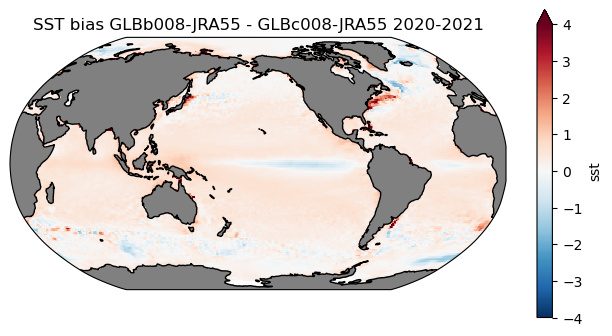

In [38]:
plot_map(sst_RTOFS.mean(dim="time") - sst_GLBc.mean(dim="time"), grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r",
         title="SST bias GLBb008-JRA55 - GLBc008-JRA55 2020-2021")

#### 4.1.2 SSS

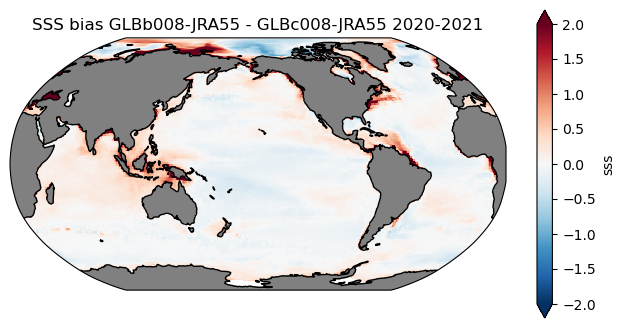

In [39]:
plot_map(sss_RTOFS.mean(dim="time") - sss_GLBc.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r",
         title="SSS bias GLBb008-JRA55 - GLBc008-JRA55 2020-2021")

#### 4.1.3 SSH

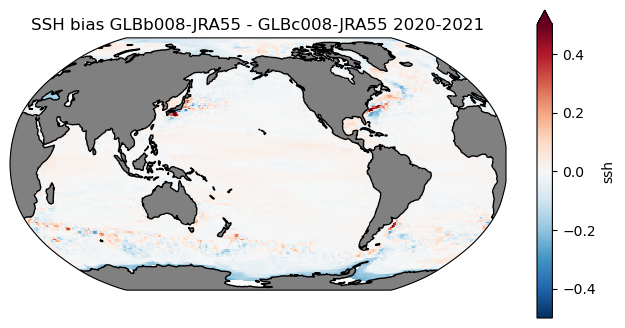

In [40]:
plot_map(ssh_RTOFS.mean(dim="time") - ssh_GLBc.mean(dim="time"), grid_1x1deg,
         vmin=-0.5, vmax=0.5, cmap="RdBu_r",
         title="SSH bias GLBb008-JRA55 - GLBc008-JRA55 2020-2021")

### 4.2 Difference with observations

#### 4.2.1 SST

In [41]:
ostia = xr.open_dataset("/work/noaa/marine/rdussin/datasets/Observations/gridded/sst_ostia_1m_2020-2021.nc")

In [42]:
sst_ostia = ostia["analysed_sst"]
sst_ostia["time"] = RTOFS["time"]

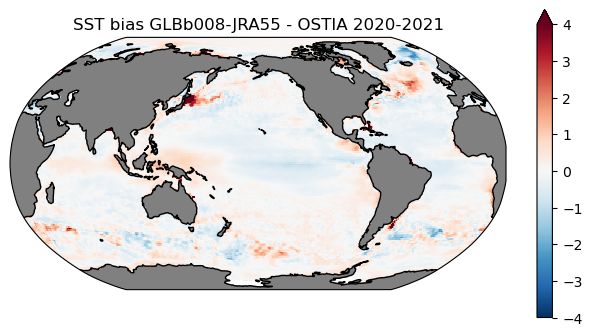

In [43]:
plot_map(sst_RTOFS.mean(dim="time") - sst_ostia.mean(dim="time") + 273.15, grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r",
         title="SST bias GLBb008-JRA55 - OSTIA 2020-2021")

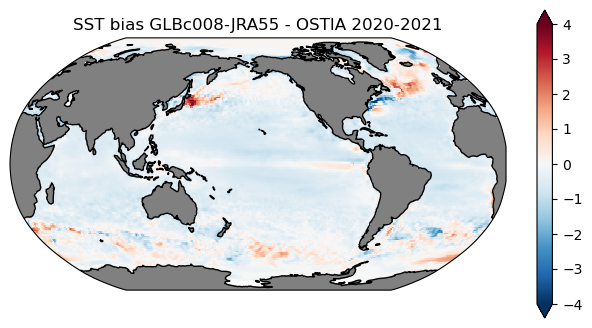

In [44]:
plot_map(sst_GLBc.mean(dim="time") - sst_ostia.mean(dim="time") + 273.15, grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r",
         title="SST bias GLBc008-JRA55 - OSTIA 2020-2021")

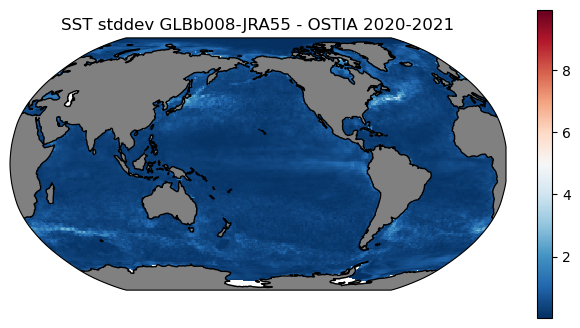

In [45]:
plot_map((sst_RTOFS - sst_ostia + 273.15).std(dim="time"), grid_1x1deg,
         title="SST stddev GLBb008-JRA55 - OSTIA 2020-2021")

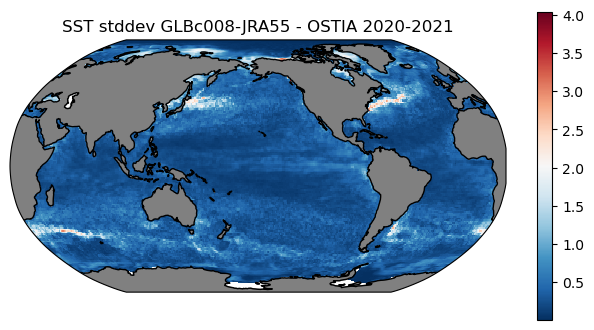

In [46]:
plot_map((sst_GLBc - sst_ostia + 273.15).std(dim="time"), grid_1x1deg,
         title="SST stddev GLBc008-JRA55 - OSTIA 2020-2021")

#### 4.2.2 SSS

In [47]:
cmems_sss = xr.open_dataset("/work/noaa/marine/rdussin/datasets/Observations/gridded/sss_cmems_1m_2020-2021.nc")

In [48]:
sos_cmems = cmems_sss["sos"]
sos_cmems["time"] = RTOFS["time"]

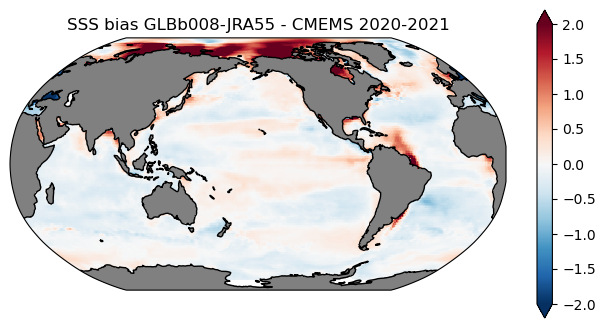

In [49]:
plot_map(sss_RTOFS.mean(dim="time") - sos_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r",
         title="SSS bias GLBb008-JRA55 - CMEMS 2020-2021")

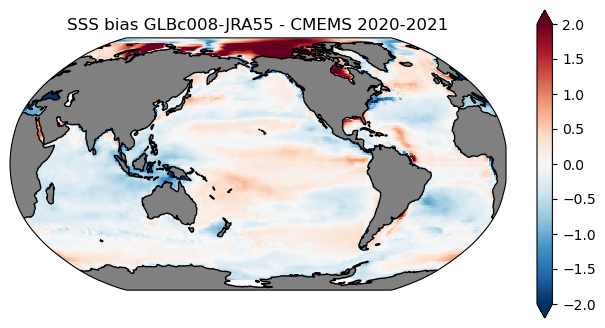

In [50]:
plot_map(sss_GLBc.mean(dim="time") - sos_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r",
         title="SSS bias GLBc008-JRA55 - CMEMS 2020-2021")

#### 4.2.2 SSH

In [51]:
cmems_ssh = xr.open_dataset("/work/noaa/marine/rdussin/datasets/Observations/gridded/ssh_cmems_1m_2020-2021.nc")

In [52]:
ssh_cmems = cmems_ssh["adt"]
ssh_cmems["time"] = RTOFS["time"]

In [53]:
def remove_glo_mean(ssh, grid_1x1deg):
    sshglo = ssh.weighted(grid_1x1deg["area"]*grid_1x1deg["mask"]).mean(dim=("x", "y"))
    return ssh - sshglo

In [54]:
ssh_cmems = remove_glo_mean(ssh_cmems, grid_1x1deg)
ssh_RTOFS = remove_glo_mean(ssh_RTOFS, grid_1x1deg)
ssh_GLBc = remove_glo_mean(ssh_GLBc, grid_1x1deg)

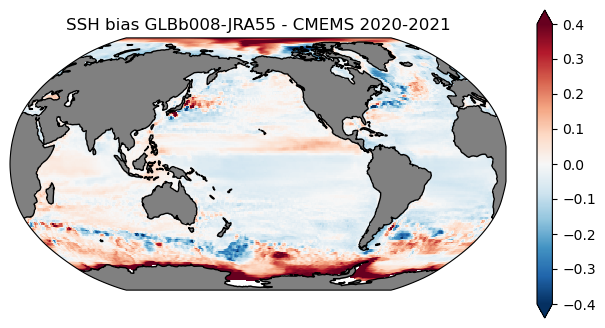

In [55]:
plot_map(ssh_RTOFS.mean(dim="time") - ssh_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-0.4, vmax=0.4, cmap="RdBu_r",
         title="SSH bias GLBb008-JRA55 - CMEMS 2020-2021")

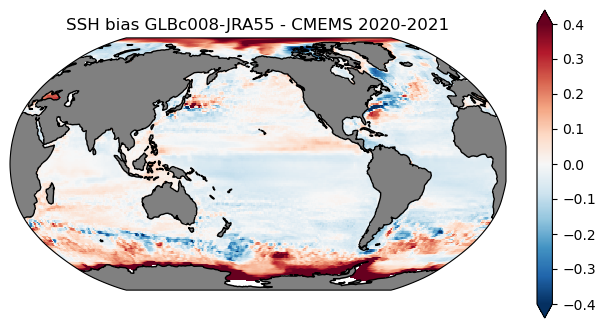

In [56]:
plot_map(ssh_GLBc.mean(dim="time") - ssh_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-0.4, vmax=0.4, cmap="RdBu_r",
         title="SSH bias GLBc008-JRA55 - CMEMS 2020-2021")